# 01. What to train on: Kaggle sentences, synthetic posts, or both?

We have two kinds of labeled text:

- **Kaggle sentences** (63,388 in `data/cv_rows.parquet`, 3 folds): plenty of them, but short sentences
  from news articles, labeled without street-type words ("Хрещатик", not "вулиці Хрещатик").
- **Synthetic posts** (5,839, `synthetic/`): look like the test posts (Telegram style, emoji, line
  breaks, addresses) and follow the test labeling style, but there are far fewer and they are written by
  an LLM.

The adversarial check showed that XLM-R separates sentences from test posts almost perfectly (AUC 0.99),
and synthetic posts less well (0.94). So we expect the synthetic posts to matter most for the score on
posts, and the sentences to add variety of place names. This notebook finds the mix.

**Fixed for every run:** XLM-R base, AdamW, lr 3e-5 with linear decay and 10% warmup, 3 epochs, batch 32,
windows of 256 tokens. Validation fold 0: the model never sees fold 0 of the sentences or of the
synthetic posts.

**Scores** (see `ner/evaluate.py`): `cv` = held-out sentences (comparable with Assignment 3), `synthetic`
= held-out synthetic posts, `half_B` = test posts with pseudo-labels that the generator never saw (our
main score), `half_A` = test posts the generator saw, `gold26` = the 26 human-labeled posts. After
submitting a run to Kaggle, add its public score to `transformers/leaderboard.csv`.

### Setup

On Colab (T4 or better): clones the repo, installs W&B and keeps every run on Drive in
`dl-a4-ner/runs`, so a disconnect loses at most the run in progress (finished runs are loaded, not
retrained). Teammates: put a shortcut to the shared `dl-a4-ner` folder in your My Drive, so all runs
land in one place. Set `WANDB_ENTITY` to the team's W&B entity to log into one shared project.
Locally the notebook runs from the repo root and writes to `transformers/runs`. To check the whole
notebook in a few minutes before using GPU time, set the environment variable `NER_SMOKE=1`: every run
shrinks to a few hundred texts and goes to `transformers/runs_smoke`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/koalla05/deep-learning-assignment4.git"
WANDB_PROJECT = "dl-a4-ner"  # None switches W&B off
WANDB_ENTITY = None  # the team's W&B entity, so all teammates log into one project

if "google.colab" in sys.modules:
    repo = Path("/content/deep-learning-assignment4")
    if not repo.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(repo)], check=True)
    else:
        subprocess.run(["git", "-C", str(repo), "pull", "-q"], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wandb"], check=True)
    from google.colab import drive

    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/dl-a4-ner/runs")
else:
    if Path.cwd().name == "transformers":
        os.chdir("..")
    OUT = Path("transformers/runs")
sys.path.insert(0, os.getcwd())
if os.environ.get("NER_SMOKE"):  # quick end-to-end check with tiny runs, see ner.train.smoke
    OUT, WANDB_PROJECT = Path("transformers/runs_smoke"), None
OUT.mkdir(parents=True, exist_ok=True)
if WANDB_ENTITY:
    os.environ["WANDB_ENTITY"] = WANDB_ENTITY
if WANDB_PROJECT:
    import wandb

    wandb.login()

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: kov-koalla (kov-koalla-kyiv-school-of-economics) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [2]:
import dataclasses

from ner import plots
from ner.data import DataSpec
from ner.train import RunConfig, load_run, run_or_load

BASE = RunConfig(name="base", model="FacebookAI/xlm-roberta-base", fold=0, tags=("01_data_mix",))


def train(name, **changes):
    cfg = dataclasses.replace(BASE, name=f"01-{name}", **changes)
    return run_or_load(cfg, OUT, WANDB_PROJECT)

## Each source alone

The two baselines. Sentences only is what Assignment 3 trained on, so its `cv` score is directly
comparable with the RNNs; the gap between `cv` and `half_B` shows the domain shift. Synthetic only shows
how far the 3,900 training posts of fold 0 get without any Kaggle data.

In [3]:
train("sentences", data=DataSpec(synthetic="none"))

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

... (3 outputs left out)

stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.014956,No log,0.015862,0.046778
2,0.005916,No log,0.011791,0.039415
3,0.002834,No log,0.012081,0.049855


eval/cv_f1,▁██
eval/gold26_f1,▁█▆
eval/half_B_f1,▁█▇
eval/sentences_loss,█▁▁
eval/sentences_runtime,█▁▃
eval/sentences_samples_per_second,▁█▆
eval/sentences_steps_per_second,▁█▆
eval/synthetic_f1,▁█▆
eval/synthetic_loss,▆▁█
eval/synthetic_runtime,█▄▁
+36,...


{'cv': {'f1': 0.91920732, 'precision': 0.9108, 'recall': 0.9278},
 'synthetic': {'f1': 0.8254818, 'precision': 0.7762, 'recall': 0.8815},
 'half_B': {'f1': 0.77419355, 'precision': 0.6917, 'recall': 0.879},
 'half_A': {'f1': 0.81172492, 'precision': 0.7423, 'recall': 0.8955},
 'gold26': {'f1': 0.69047619, 'precision': 0.5577, 'recall': 0.9062},
 'train_minutes': 25.4}

In [4]:
train("synthetic", data=DataSpec(sentences=0))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.019075,No log,0.111988,0.016247
2,0.011762,No log,0.069714,0.011635
3,0.006355,No log,0.049357,0.009133


eval/cv_f1,▁▅█
eval/gold26_f1,▁▅█
eval/half_B_f1,▁▅█
eval/sentences_loss,█▃▁
eval/sentences_runtime,█▁▃
eval/sentences_samples_per_second,▁█▆
eval/sentences_steps_per_second,▁█▆
eval/synthetic_f1,▁▇█
eval/synthetic_loss,█▃▁
eval/synthetic_runtime,▁██
+36,...


{'cv': {'f1': 0.76399512, 'precision': 0.7184, 'recall': 0.8157},
 'synthetic': {'f1': 0.94463277, 'precision': 0.9337, 'recall': 0.9558},
 'half_B': {'f1': 0.83030303, 'precision': 0.7919, 'recall': 0.8726},
 'half_A': {'f1': 0.85680473, 'precision': 0.8172, 'recall': 0.9005},
 'gold26': {'f1': 0.78947368, 'precision': 0.6818, 'recall': 0.9375},
 'train_minutes': 8.4}

## Mixes

All 42k training sentences outnumber the synthetic posts about 11 to 1, so the model mostly learns the
sentence style. We try three ways to give the posts more weight: fewer sentences (a random 10k sample),
repeating every synthetic post 3 times per epoch, and two stages (first sentences, then posts only,
with a lower learning rate, so the last thing the model learns is the post style and labeling rules).

In [5]:
train("sent10k-syn", data=DataSpec(sentences=10_000))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=10,000, synthetic=all -> 13,942 texts, 14,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.020638,No log,0.030947,0.018077
2,0.014254,No log,0.017100,0.011123
3,0.005541,No log,0.017497,0.010264


eval/cv_f1,▁▇█
eval/gold26_f1,▁▇█
eval/half_B_f1,▁▅█
eval/sentences_loss,█▁▁
eval/sentences_runtime,▁█▃
eval/sentences_samples_per_second,█▁▆
eval/sentences_steps_per_second,█▁▆
eval/synthetic_f1,▁▄█
eval/synthetic_loss,█▂▁
eval/synthetic_runtime,█▁█
+36,...


{'cv': {'f1': 0.90390671, 'precision': 0.8908, 'recall': 0.9174},
 'synthetic': {'f1': 0.94758673, 'precision': 0.9377, 'recall': 0.9577},
 'half_B': {'f1': 0.85714286, 'precision': 0.8198, 'recall': 0.8981},
 'half_A': {'f1': 0.89022919, 'precision': 0.8642, 'recall': 0.9179},
 'gold26': {'f1': 0.84210526, 'precision': 0.7273, 'recall': 1.0},
 'train_minutes': 13.8}

In [6]:
train("sentall-syn", data=DataSpec())

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=all -> 46,201 texts, 46,440 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.016914,No log,0.013706,0.014676
2,0.008128,No log,0.013328,0.013968
3,0.004525,No log,0.012457,0.012394


eval/cv_f1,▁▆█
eval/gold26_f1,▁▅█
eval/half_B_f1,▁▇█
eval/sentences_loss,█▆▁
eval/sentences_runtime,▂█▁
eval/sentences_samples_per_second,▇▁█
eval/sentences_steps_per_second,▇▁█
eval/synthetic_f1,▆▁█
eval/synthetic_loss,█▆▁
eval/synthetic_runtime,▁▂█
+36,...


{'cv': {'f1': 0.91928093, 'precision': 0.9126, 'recall': 0.926},
 'synthetic': {'f1': 0.93882175, 'precision': 0.9304, 'recall': 0.9474},
 'half_B': {'f1': 0.85046729, 'precision': 0.8323, 'recall': 0.8694},
 'half_A': {'f1': 0.87439614, 'precision': 0.8498, 'recall': 0.9005},
 'gold26': {'f1': 0.82666667, 'precision': 0.7209, 'recall': 0.9688},
 'train_minutes': 31.4}

In [7]:
train("sentall-syn3", data=DataSpec(synthetic_repeat=3))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=allx3 -> 54,085 texts, 54,802 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.012548,No log,0.013550,0.011648
2,0.007107,No log,0.013323,0.011443
3,0.001564,No log,0.013722,0.012197


eval/cv_f1,▁▆█
eval/gold26_f1,▁█▇
eval/half_B_f1,▁▇█
eval/sentences_loss,▅▁█
eval/sentences_runtime,█▁▇
eval/sentences_samples_per_second,▁█▂
eval/sentences_steps_per_second,▁█▂
eval/synthetic_f1,▁█▃
eval/synthetic_loss,▃▁█
eval/synthetic_runtime,▁▅█
+36,...


{'cv': {'f1': 0.92020214, 'precision': 0.9138, 'recall': 0.9267},
 'synthetic': {'f1': 0.93875236, 'precision': 0.9314, 'recall': 0.9463},
 'half_B': {'f1': 0.85932722, 'precision': 0.8265, 'recall': 0.8949},
 'half_A': {'f1': 0.89049338, 'precision': 0.8625, 'recall': 0.9204},
 'gold26': {'f1': 0.74074074, 'precision': 0.6122, 'recall': 0.9375},
 'train_minutes': 42.2}

In [8]:
train(
    "two-stage",
    data=DataSpec(synthetic="none"),
    epochs=2,
    stage2_data=DataSpec(sentences=0),
    stage2_epochs=2,
    stage2_lr=2e-5,
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.014631,No log,0.013755,0.041083
2,0.005880,No log,0.011559,0.043826


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.016320,No log,0.016984,0.012802
2,0.010598,No log,0.016110,0.009391


eval/cv_f1,▄█▁▄
eval/gold26_f1,▁▂▅█
eval/half_B_f1,▁▃▄█
eval/sentences_loss,▄▁█▇
eval/sentences_runtime,█▁▆▁
eval/sentences_samples_per_second,▁█▃█
eval/sentences_steps_per_second,▁█▃▇
eval/synthetic_f1,▂▁▇█
eval/synthetic_loss,▇█▂▁
eval/synthetic_runtime,█▁▇▁
+36,...


{'cv': {'f1': 0.89704587, 'precision': 0.8903, 'recall': 0.9039},
 'synthetic': {'f1': 0.94598155, 'precision': 0.9345, 'recall': 0.9577},
 'half_B': {'f1': 0.87227414, 'precision': 0.8537, 'recall': 0.8917},
 'half_A': {'f1': 0.89052891, 'precision': 0.8808, 'recall': 0.9005},
 'gold26': {'f1': 0.80519481, 'precision': 0.6889, 'recall': 0.9688},
 'train_minutes': 22.6}

## Filtering the synthetic posts by the adversarial score

`synthetic_adversarial.ipynb` gave every synthetic post a test-likeness percentile. Here we keep only
the more test-like half, or keep all posts but weight each post's loss by its percentile (mean weight 1).
Set `MIX` to the best mix from above before running these (default: 10k sentences).

In [9]:
MIX = DataSpec(sentences=10_000)

train("syn-top50", data=dataclasses.replace(MIX, synthetic="top50"))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=10,000, synthetic=top50 -> 11,942 texts, 12,070 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.020758,No log,0.017868,0.017518
2,0.014429,No log,0.017319,0.012886
3,0.007036,No log,0.017532,0.013045


eval/cv_f1,▁▃█
eval/gold26_f1,▁▇█
eval/half_B_f1,▁▅█
eval/sentences_loss,█▁▄
eval/sentences_runtime,▁▅█
eval/sentences_samples_per_second,█▄▁
eval/sentences_steps_per_second,█▄▁
eval/synthetic_f1,▁██
eval/synthetic_loss,█▁▁
eval/synthetic_runtime,▄▁█
+36,...


{'cv': {'f1': 0.90584945, 'precision': 0.892, 'recall': 0.9201},
 'synthetic': {'f1': 0.94345294, 'precision': 0.9303, 'recall': 0.9569},
 'half_B': {'f1': 0.8575804, 'precision': 0.826, 'recall': 0.8917},
 'half_A': {'f1': 0.8864994, 'precision': 0.8529, 'recall': 0.9229},
 'gold26': {'f1': 0.77922078, 'precision': 0.6667, 'recall': 0.9375},
 'train_minutes': 11.0}

In [10]:
train("syn-weighted", data=dataclasses.replace(MIX, weight_by_test_like=True))

wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=10,000, synthetic=all, weighted -> 13,942 texts, 14,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.020469,No log,0.025572,0.014895
2,0.014354,No log,0.016798,0.011376
3,0.006203,No log,0.016262,0.010546


eval/cv_f1,▁▇█
eval/gold26_f1,▁▅█
eval/half_B_f1,▁▆█
eval/sentences_loss,█▁▁
eval/sentences_runtime,██▁
eval/sentences_samples_per_second,▁▁█
eval/sentences_steps_per_second,▁▁█
eval/synthetic_f1,▁▄█
eval/synthetic_loss,█▂▁
eval/synthetic_runtime,█▁▂
+36,...


{'cv': {'f1': 0.902726, 'precision': 0.8887, 'recall': 0.9171},
 'synthetic': {'f1': 0.94714987, 'precision': 0.9383, 'recall': 0.9562},
 'half_B': {'f1': 0.85276074, 'precision': 0.8225, 'recall': 0.8854},
 'half_A': {'f1': 0.89987937, 'precision': 0.8735, 'recall': 0.9279},
 'gold26': {'f1': 0.83783784, 'precision': 0.7381, 'recall': 0.9688},
 'train_minutes': 13.8}

## Results

Runs that are not finished yet (or were run by a teammate into another folder) are skipped.

In [11]:
NAMES = ["sentences", "synthetic", "sent10k-syn", "sentall-syn", "sentall-syn3", "two-stage", "syn-top50", "syn-weighted"]
runs = {n: load_run(OUT, f"01-{n}") for n in NAMES if (OUT / f"01-{n}" / "metrics.json").exists()}
plots.results_table(runs, leaderboard="transformers/leaderboard.csv").round(4)

,cv,synthetic,half_B,half_A,gold26,minutes,public_lb
sentences,0.9192,0.8255,0.7742,0.8117,0.6905,25.4,None
synthetic,0.7640,0.9446,0.8303,0.8568,0.7895,8.4,None
sent10k-syn,0.9039,0.9476,0.8571,0.8902,0.8421,13.8,None
sentall-syn,0.9193,0.9388,0.8505,0.8744,0.8267,31.4,None
sentall-syn3,0.9202,0.9388,0.8593,0.8905,0.7407,42.2,None
two-stage,0.8970,0.9460,0.8723,0.8905,0.8052,22.6,None
syn-top50,0.9058,0.9435,0.8576,0.8865,0.7792,11.0,None
syn-weighted,0.9027,0.9471,0.8528,0.8999,0.8378,13.8,None


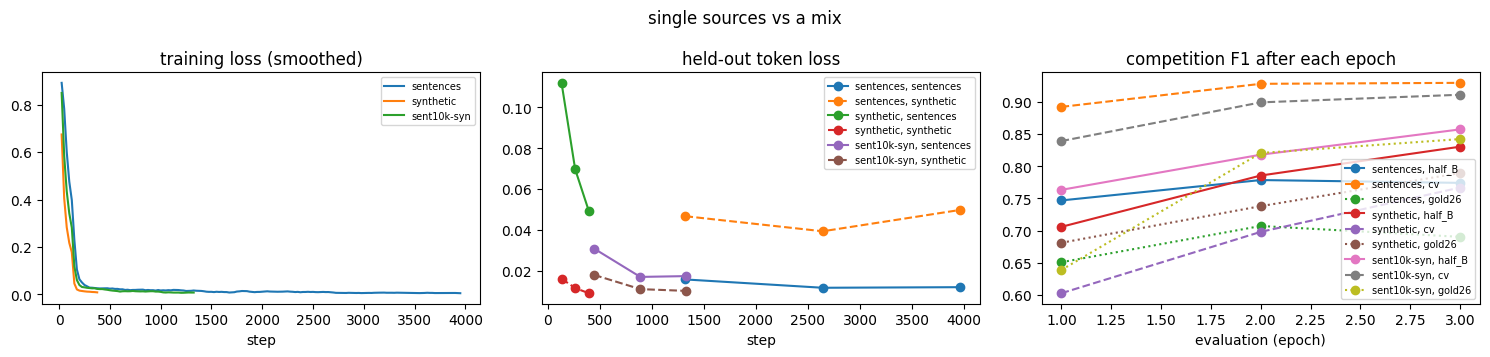

In [12]:
plots.plot_curves({n: runs[n] for n in ["sentences", "synthetic", "sent10k-syn"] if n in runs}, title="single sources vs a mix")

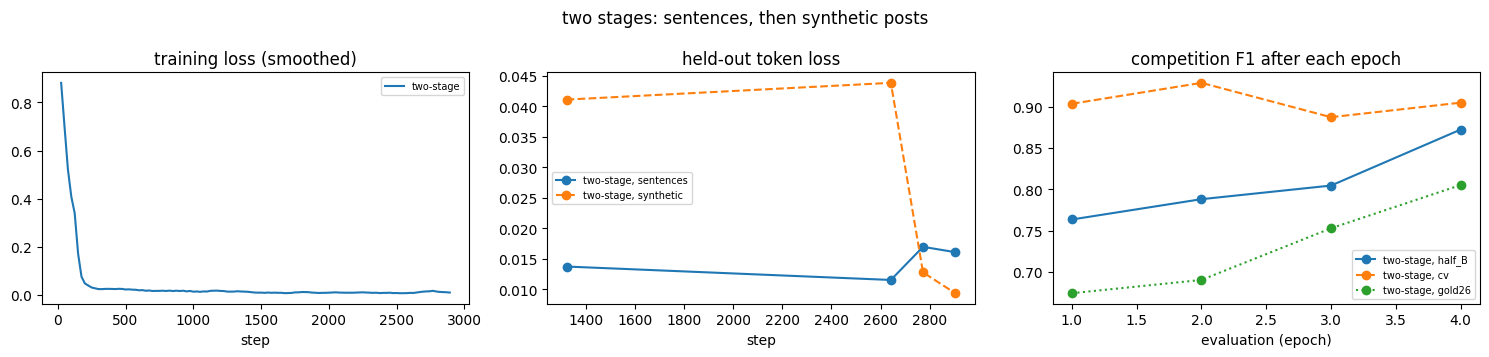

In [13]:
plots.plot_curves({n: runs[n] for n in ["two-stage"] if n in runs}, title="two stages: sentences, then synthetic posts")

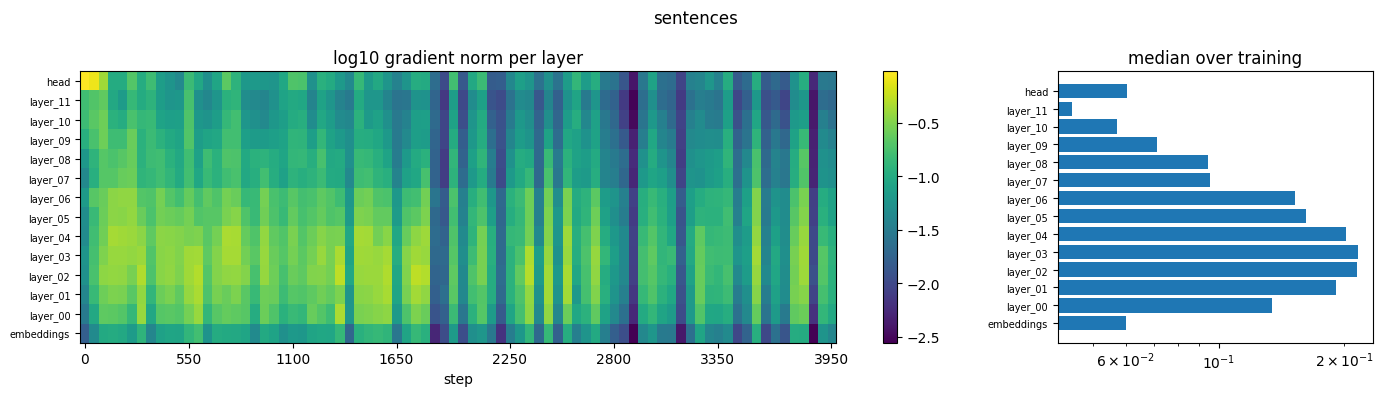

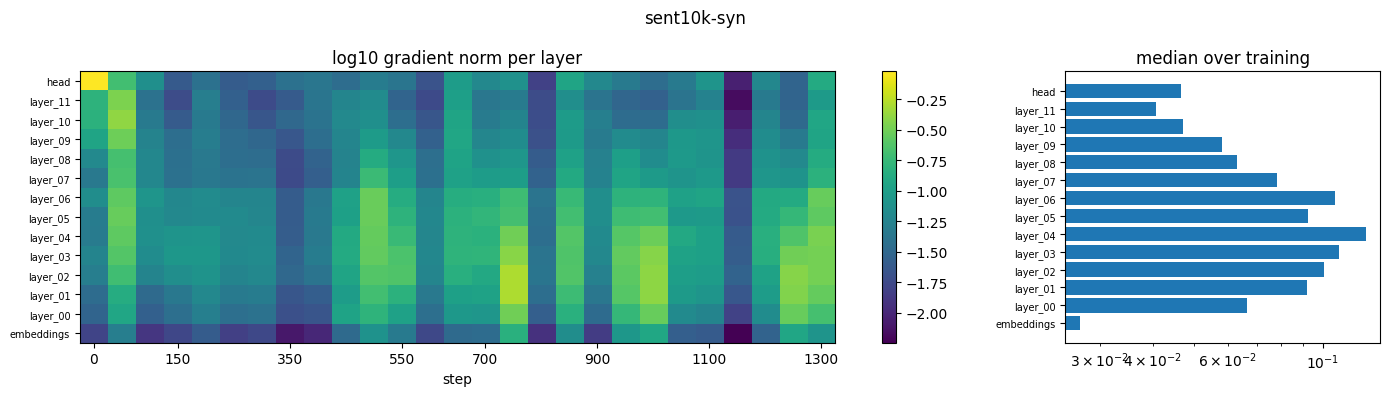

In [14]:
for n in ["sentences", "sent10k-syn"]:
    if n in runs:
        plots.plot_grad_flow(runs[n], title=n)

## Conclusions

All 8 runs finished on a T4 in fp16 (no `nan` losses), 2.8 h in total. `half_B` has 238 posts with 314
places, so differences of 1-2 points are within noise. To check this we ran a paired bootstrap over posts
(5,000 resamples) on the runs' submissions: the 95% interval of each run's `half_B` is about ±0.04.

| run | cv | half_B | half_A | gold26 | minutes |
| --- | --- | --- | --- | --- | --- |
| sentences | 0.919 | 0.774 | 0.812 | 0.690 | 25 |
| synthetic | 0.764 | 0.830 | 0.857 | 0.789 | 8 |
| sent10k-syn | 0.904 | 0.857 | 0.890 | 0.842 | 14 |
| sentall-syn | 0.919 | 0.851 | 0.874 | 0.827 | 31 |
| sentall-syn3 | 0.920 | 0.859 | 0.891 | 0.741 | 42 |
| **two-stage** | 0.897 | **0.872** | 0.891 | 0.805 | 23 |
| syn-top50 | 0.906 | 0.858 | 0.887 | 0.779 | 11 |
| syn-weighted | 0.903 | 0.853 | 0.900 | 0.838 | 14 |

**Domain shift.** The model trained on sentences only scores 0.919 on held-out sentences but 0.774 on
`half_B`, a gap of 0.145. The gap comes mostly from precision (0.69, against recall 0.88): the model
finds the places but adds many that the test labeling does not count, or cuts them differently
(street-type words, generic places). The 3,900 synthetic posts alone already beat all 42k sentences on
`half_B` (0.830 vs 0.774), although they score only 0.764 on sentences.

**Mixing both sources** adds another 2-4 points (0.850-0.872 on every mix) and closes between half and two thirds of
the gap. The way of mixing matters less than mixing at all. **Two stages** (2 epochs on sentences, then 2 on
posts at lr 2e-5) is the best on `half_B` (0.872) and has the highest precision (0.854). In the paired
bootstrap it is better than each of the other mixes in 78-92% of resamples. That is a consistent lead,
but not a certain one. Its cost is the sentence score (0.897, -0.022 against sentences only): the second
stage moves the model to the post style and labeling rules, which is what the test needs. Of the
one-stage mixes, 10k sentences + posts is as good as all sentences + 3x posts (0.857 vs 0.859) in a third
of the time.

**half_A vs half_B.** Every run scores 2-5 points higher on `half_A`. The runs that see no synthetic data
show the same gap (sentences only: +0.04), so most of it is a difference between the two samples of posts,
not leakage through the generator. Two-stage has the smallest gap (+0.018). `half_B` remains the honest
score.

**Filtering by the adversarial score does not help.** Keeping only the more test-like half (0.858) or
weighting by test-likeness (0.853) is no better than all posts (0.857, all three on the 10k-sentence mix).
Half the posts is less variety of place names, and that cancels out whatever we gain on style. We keep all
synthetic posts.

**gold26** (26 posts, 32 places) moves by up to 10 points between runs that are equal on `half_B`
(sentall-syn3 0.741 vs sent10k-syn 0.842), so it is too small to decide anything. It agrees with `half_B`
on the main points: sentences only is the worst, and every mix beats both single sources.

**Is training adequate?** (plots above)
- The training loss falls smoothly in every run, with no spikes.
- *Sentences only overfits to the sentence domain.* After epoch 2 the held-out loss on synthetic posts
  rises (0.039 -> 0.050) and `half_B` goes down while `cv` still goes up. More sentence epochs make the model
  worse on posts.
- *Two-stage:* in stage 2 the synthetic loss drops from 0.044 to 0.009, and the sentence loss rises only
  slightly (0.012 -> 0.017), so the model forgets little. `half_B` jumps from 0.80 to 0.87 and is still
  rising at the last evaluation, so a longer stage 2 may help (tested in 02).
- *Gradient flow:* every layer gets gradient norms of about 1e-2 to 1e-1 for the whole run. Nothing
  vanishes or explodes. The norms are largest in layers 2-4 and smallest in layer 11 and the embeddings.
  The randomly initialized head starts with the largest gradients, which is the reason for warmup. Dark
  vertical stripes are batches with few places, so the loss is small.

**Decision:** two stages. `ner/recipes.py` now has `DATA = DataSpec(synthetic="none")` with 2 epochs,
and `STAGE2` = all synthetic posts for 2 epochs at lr 2e-5. If GPU time is short (XLM-R large),
`sent10k-syn` is the cheaper alternative within noise.

Still to do: submit `01-sentences` and `01-two-stage` to Kaggle and add the public scores to
`transformers/leaderboard.csv`, to check that `half_B` ranks runs the same way as the leaderboard.